In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


--- ORIGINALES ---

Modelo 1: Y_hat = 24.14012629 +9.400014975e-07 * X1
Estimadores [beta1, beta2, ...]: [2.41401263e+01 9.40001498e-07]
R² = 0.4647252907
  Y          Y_hat          Y - Y_hat
 11.00     24.14020286      -13.140203
 13.00     24.14029669      -11.140297
 14.00     24.14038050       -10.14038
 15.00     24.14050552      -9.1405055
 17.00     24.14097027      -7.1409703
 18.00     24.14138536      -6.1413854
 19.00     24.14200460      -5.1420046
 21.00     24.14430654      -3.1443065
 22.00     24.14636249      -2.1463625
 26.00     24.17101439       1.8289856
 28.00     24.20886902        3.791131
 31.00     24.36836018       6.6316398
 32.00     24.48061124       7.5193888
 34.00     24.89788948       9.1021105
 35.50     25.52086083       9.9791392
 36.00     25.82655927       10.173441
 38.00     27.89335190       10.106648
 40.00     32.49308349       7.5069165
 40.60     34.75881599        5.841184
 41.00     36.60127410       4.3987259
 42.00     42.72997445    

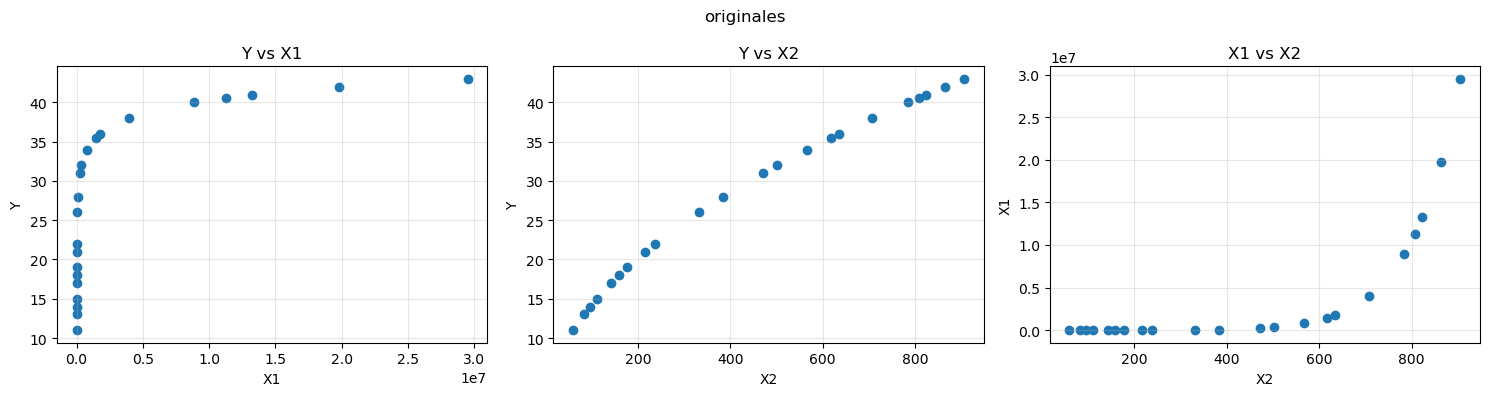

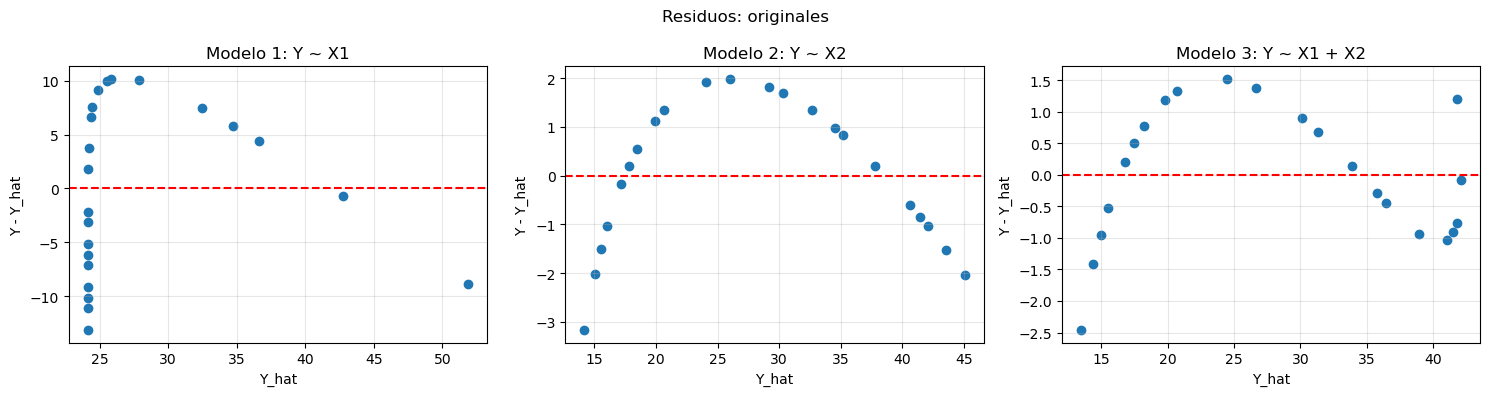

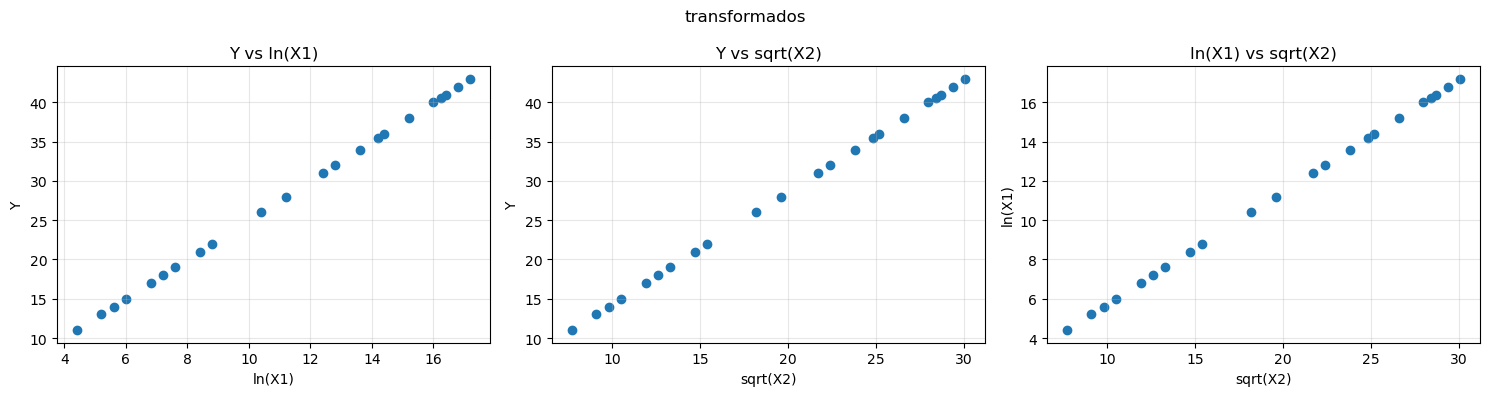

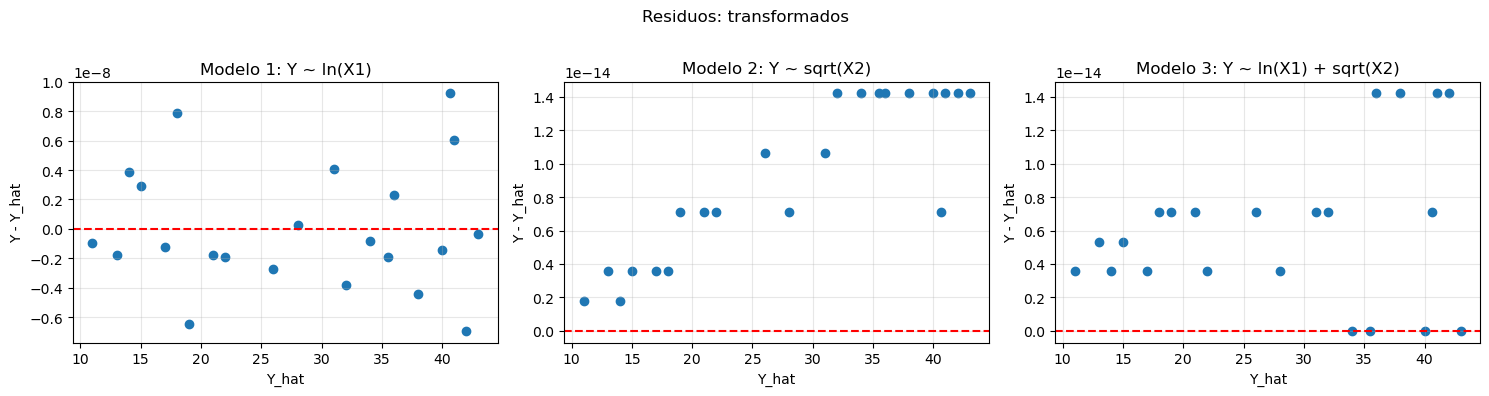

In [3]:
# Columnas: Y, X1, X2 (22 observaciones de las imágenes).
datos = np.array([
    [11, 81.4508687, 59.29],
    [13, 181.272242, 82.81],
    [14, 270.426407, 96.04],
    [15, 403.428793, 110.25],
    [17, 897.847292, 141.61],
    [18, 1339.43076, 158.76],
    [19, 1998.1959, 176.89],
    [21, 4447.06675, 216.09],
    [22, 6634.24401, 237.16],
    [26, 32859.6257, 331.24],
    [28, 73130.4418, 384.16],
    [31, 242801.617, 470.89],
    [32, 362217.45, 501.76],
    [34, 806129.759, 566.44],
    [35.5, 1468864.19, 617.5225],
    [36, 1794074.77, 635.04],
    [38, 3992786.84, 707.56],
    [40, 8886110.52, 784],
    [40.6, 11296460.4, 807.6964],
    [41, 13256519.1, 823.69],
    [42, 19776402.7, 864.36],
    [43, 29502925.9, 906.01],
], dtype=float)

Y, X1, X2 = datos.T
salida = Path("resultados")
salida.mkdir(exist_ok=True)


def ajustar(y, predictores):
    """Mínimos cuadrados con intercepto y escala numérica estable."""
    X = np.column_stack(predictores)
    medias = X.mean(axis=0)
    escalas = X.std(axis=0)
    Z = np.column_stack([np.ones(len(y)), (X - medias) / escalas])
    coef, _, rango, singulares = np.linalg.lstsq(Z, y, rcond=None)
    pendientes = coef[1:] / escalas
    beta = np.r_[coef[0] - medias @ pendientes, pendientes]
    y_hat = beta[0] + X @ beta[1:]
    residuos = y - y_hat
    r2 = 1 - np.sum(residuos**2) / np.sum((y - y.mean())**2)
    return beta, y_hat, residuos, r2, singulares[0] / singulares[-1]


def analizar(x1, x2, nombre1, nombre2, etapa):
    # En "A vs B", B se representa en el eje horizontal.
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    pares = [(x1, Y, nombre1, "Y"),
             (x2, Y, nombre2, "Y"),
             (x2, x1, nombre2, nombre1)]
    for ax, (x, y, etiqueta_x, etiqueta_y) in zip(axes, pares):
        ax.scatter(x, y)
        ax.set(xlabel=etiqueta_x, ylabel=etiqueta_y,
               title=f"{etiqueta_y} vs {etiqueta_x}")
        ax.grid(alpha=0.3)
    fig.suptitle(etapa)
    fig.tight_layout()
    fig.savefig(salida / f"{etapa}_dispersion.png", dpi=180)

    modelos = [([x1], [nombre1]), ([x2], [nombre2]),
               ([x1, x2], [nombre1, nombre2])]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    tabla = [Y]
    columnas = ["Y"]
    print(f"\n--- {etapa.upper()} ---")

    for i, ((predictores, nombres), ax) in enumerate(zip(modelos, axes), 1):
        beta, y_hat, residuos, r2, condicion = ajustar(Y, predictores)
        ecuacion = f"Y_hat = {beta[0]:.10g}"
        for b, variable in zip(beta[1:], nombres):
            ecuacion += f" {b:+.10g} * {variable}"
        print(f"\nModelo {i}: {ecuacion}")
        print(f"Estimadores [beta1, beta2, ...]: {beta}")
        print(f"R² = {r2:.10f}")
        print("  Y          Y_hat          Y - Y_hat")
        for y, yh, e in zip(Y, y_hat, residuos):
            print(f"{y:6.2f}  {yh:14.8f}  {e:14.8g}")
        if condicion > 1e8:
            print("Aviso: predictores casi colineales; los coeficientes "
                  "individuales son muy sensibles al redondeo.")

        # Residuos frente a los valores ajustados, para cada modelo.
        ax.scatter(y_hat, residuos)
        ax.axhline(0, color="red", linestyle="--")
        ax.set(xlabel="Y_hat", ylabel="Y - Y_hat",
               title=f"Modelo {i}: Y ~ {' + '.join(nombres)}")
        ax.grid(alpha=0.3)
        tabla.extend([y_hat, residuos])
        columnas.extend([f"Y_hat_M{i}", f"residuo_M{i}"])

    fig.suptitle(f"Residuos: {etapa}")
    fig.tight_layout()
    fig.savefig(salida / f"{etapa}_residuos.png", dpi=180)
    np.savetxt(salida / f"{etapa}_resultados.csv",
               np.column_stack(tabla), delimiter=",",
               header=",".join(columnas), comments="", fmt="%.12g")


analizar(X1, X2, "X1", "X2", "originales")

# ln es el logaritmo natural. Y permanece igual.
if np.any(X1 <= 0) or np.any(X2 < 0):
    raise ValueError("Se requiere X1 > 0 y X2 >= 0.")
analizar(np.log(X1), np.sqrt(X2), "ln(X1)", "sqrt(X2)", "transformados")

plt.show()
